# 实践实验：用于手写数字识别的神经网络（多类别）

在本练习中，你将使用神经网络来识别手写的数字 0-9。


# 大纲
- [ 1 - 软件包 ](#1)
- [ 2 - ReLU 激活](#2)
- [ 3 - Softmax 函数](#3)
  - [ 练习 1](#ex01)
- [ 4 - 神经网络](#4)
  - [ 4.1 问题陈述](#4.1)
  - [ 4.2 数据集](#4.2)
  - [ 4.3 模型表示](#4.3)
  - [ 4.4 Tensorflow 模型实现](#4.4)
  - [ 4.5 Softmax 的放置位置](#4.5)
    - [ 练习 2](#ex02)


_**注意：** 为防止自动评分器报错，你不得编辑或删除本笔记本中不参与评分的单元格。也请不要添加任何新单元格。
**一旦你通过了本次作业** 并想试验任何不参与评分的代码，你可以按照本笔记本底部的说明操作。_

<a name="1"></a>
## 1 - 软件包

首先，让我们运行下面的单元格，导入本次作业中你需要的所有软件包。
- [numpy](https://numpy.org/) 是用 Python 进行科学计算的基础软件包。
- [matplotlib](http://matplotlib.org) 是 Python 中流行的绘图库。
- [tensorflow](https://www.tensorflow.org/) 是一个流行的机器学习平台。

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.activations import linear, relu, sigmoid
%matplotlib widget
import matplotlib.pyplot as plt
plt.style.use('./deeplearning.mplstyle')

import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)

from public_tests import * 

from autils import *
from lab_utils_softmax import plt_softmax
np.set_printoptions(precision=2)

<a name="2"></a>
## 2 - ReLU 激活
本周引入了一种新的激活函数，即修正线性单元（Rectified Linear Unit, ReLU）。
$$ a = max(0,z) \quad\quad\text {\# ReLU 函数} $$

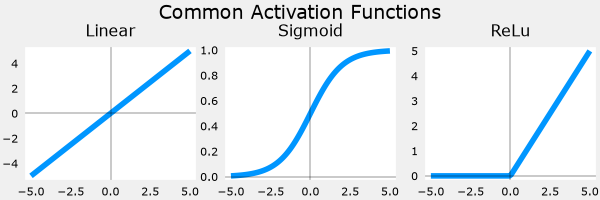

In [2]:
plt_act_trio()

<img align="right" src="./images/C2_W2_ReLu.png"     style=" width:380px; padding: 10px 20px; " >
右侧来自课程的例子展示了 ReLU 的一个应用。在这个例子中，派生出的"意识"（awareness）特征不是二元的，而是有一个连续的取值范围。sigmoid 最适合开/关或二元的情形。ReLU 则提供一个连续的线性关系。此外，它还有一个输出为零的"关"区间。
这个"关"的特性使 ReLU 成为一种非线性激活。为什么需要这样？这使得多个单元能够对最终的函数作出贡献而互不干扰。这一点在配套的可选实验中会有更深入的探讨。

<a name="3"></a>
## 3 - Softmax 函数
一个多类别神经网络会产生 N 个输出。其中一个输出被选为预测答案。在输出层，由一个线性函数生成一个向量 $\mathbf{z}$，它被送入一个 softmax 函数。softmax 函数把 $\mathbf{z}$ 转换成一个概率分布，如下所述。应用 softmax 之后，每个输出都会介于 0 和 1 之间，且所有输出之和为 1。它们可以被解释为概率。softmax 的较大输入将对应较大的输出概率。
<center>  <img  src="./images/C2_W2_NNSoftmax.PNG" width="600" />

softmax 函数可以写成：
$$a_j = \frac{e^{z_j}}{ \sum_{k=0}^{N-1}{e^{z_k} }} \tag{1}$$

其中 $z = \mathbf{w} \cdot \mathbf{x} + b$，N 是输出层中特征/类别的数量。

<a name="ex01"></a>
### 练习 1
让我们来创建一个 NumPy 实现：

In [3]:
# UNQ_C1
# GRADED CELL: my_softmax

def my_softmax(z):  
    """ Softmax converts a vector of values to a probability distribution.
    Args:
      z (ndarray (N,))  : input data, N features
    Returns:
      a (ndarray (N,))  : softmax of z
    """    
    ### START CODE HERE ### 
    a=np.exp(z)/np.sum(np.exp(z))
    
    
    
        
    
        
    
    
    ### END CODE HERE ### 
    return a

In [4]:
z = np.array([1., 2., 3., 4.])
a = my_softmax(z)
atf = tf.nn.softmax(z)
print(f"my_softmax(z):         {a}")
print(f"tensorflow softmax(z): {atf}")

# BEGIN UNIT TEST  
test_my_softmax(my_softmax)
# END UNIT TEST  

my_softmax(z):         [0.03 0.09 0.24 0.64]
tensorflow softmax(z): [0.03 0.09 0.24 0.64]
 All tests passed.


<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    一种实现方式是先用一个 for 循环构建分母，然后再用第二个循环计算每个输出。

```python
def my_softmax(z):
    N = len(z)
    a =                     # 把 a 初始化为零
    ez_sum =                # 把 sum 初始化为零
    for k in range(N):      # 遍历输出的数量
        ez_sum +=           # 对 exp(z[k]) 求和以构建共享的分母

    for j in range(N):      # 再次遍历输出的数量
        a[j] =              # 用每个输出的指数除以分母
    return(a)
```
<details>
  <summary><font size="3" color="darkgreen"><b>点击查看代码</b></font></summary>

```python
def my_softmax(z):
    N = len(z)
    a = np.zeros(N)
    ez_sum = 0
    for k in range(N):
        ez_sum += np.exp(z[k])
    for j in range(N):
        a[j] = np.exp(z[j])/ez_sum
    return(a)

或者，一个向量化的实现：

def my_softmax(z):
    ez = np.exp(z)
    a = ez/np.sum(ez)
    return(a)

```


在下面，改变 `z` 输入的取值。请特别注意分子中的指数函数如何放大了数值之间微小的差异。同时请注意，输出值之和为 1。

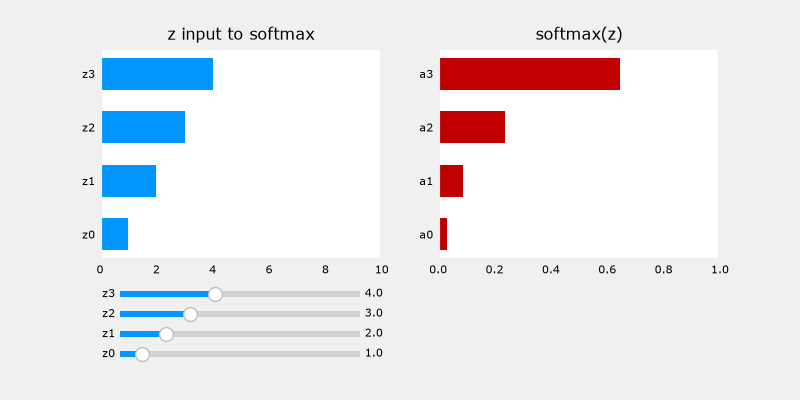

In [5]:
plt.close("all")
plt_softmax(my_softmax)

<a name="4"></a>
## 4 - 神经网络

在上周的作业中，你实现了一个用于二元分类的神经网络。本周你将把它扩展到多类别分类。这将用到 softmax 激活。


<a name="4.1"></a>
### 4.1 问题陈述

在本练习中，你将使用神经网络来识别十个手写数字，0-9。这是一个多类别分类任务，需要从 n 个选项中选出一个。自动化的手写数字识别如今被广泛使用——从识别邮件信封上的邮政编码，到识别银行支票上书写的金额。


<a name="4.2"></a>
### 4.2 数据集

你将从加载本任务的数据集开始。
- 下面展示的 `load_data()` 函数会把数据加载到变量 `X` 和 `y` 中


- 该数据集包含 5000 个手写数字的训练样本 $^1$。

    - 每个训练样本都是该数字的一张 20 像素 x 20 像素的灰度图像。
        - 每个像素由一个浮点数表示，指示该位置的灰度强度。
        - 这个 20 x 20 的像素网格被"展开"（unrolled）成一个 400 维的向量。
        - 每个训练样本成为我们数据矩阵 `X` 中的一行。
        - 这样就得到一个 5000 x 400 的矩阵 `X`，其中每一行都是一个手写数字图像的训练样本。

$$X =
\left(\begin{array}{cc}
--- (x^{(1)}) --- \\
--- (x^{(2)}) --- \\
\vdots \\
--- (x^{(m)}) ---
\end{array}\right)$$

- 训练集的第二部分是一个 5000 x 1 维的向量 `y`，它包含训练集的标签
    - 如果图像是数字 `0`，则 `y = 0`；如果图像是数字 `4`，则 `y = 4`，以此类推。

$^1$<sub> 这是 MNIST 手写数字数据集的一个子集（http://yann.lecun.com/exdb/mnist/）</sub>

In [6]:
# load dataset
X, y = load_data()

#### 4.2.1 查看这些变量
让我们进一步熟悉你的数据集。
- 一个好的起点是打印出每个变量，看看它包含什么。

下面的代码打印变量 `X` 和 `y` 中的第一个元素。

In [7]:
print ('The first element of X is: ', X[0])

The first element of X is:  [ 0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  8.56e-06  1.94e-06 -7.37e-04
 -8.13e-03 -1.86e-02 -1.87e-02 -1.88e-02 -1.91e-02 -1.64e-02 -3.78e-03
  3.30e-04  1.28e-05  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  1.16e-04  1.20e-04 -1.40e-02 -2.85e-02  8.04e-02
  2.67e-01  2.74e-01  2.79e-01  2.74e-01  2.25e-0

In [8]:
print ('The first element of y is: ', y[0,0])
print ('The last element of y is: ', y[-1,0])

The first element of y is:  0
The last element of y is:  9


#### 4.2.2 检查变量的维度

熟悉数据的另一种方式是查看它的维度。请打印 `X` 和 `y` 的形状，看看你的数据集中有多少个训练样本。

In [9]:
print ('The shape of X is: ' + str(X.shape))
print ('The shape of y is: ' + str(y.shape))

The shape of X is: (5000, 400)
The shape of y is: (5000, 1)


#### 4.2.3 可视化数据

你将从可视化训练集的一个子集开始。
- 在下面的单元格中，代码从 `X` 中随机选择 64 行，把每一行映射回一张 20 像素 x 20 像素的灰度图像，并把这些图像一起显示出来。
- 每张图像的标签显示在图像上方

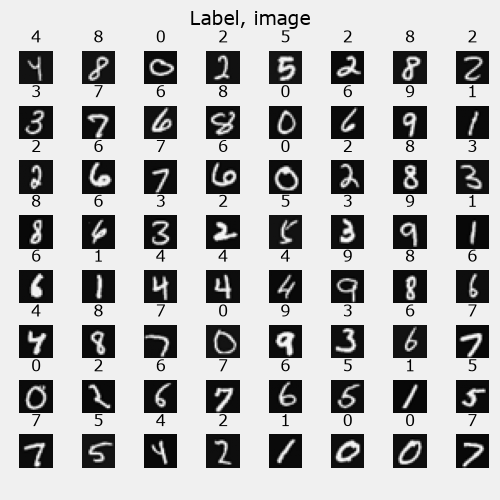

In [10]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(5,5))
fig.tight_layout(pad=0.13,rect=[0, 0.03, 1, 0.91]) #[left, bottom, right, top]

#fig.tight_layout(pad=0.5)
widgvis(fig)
for i,ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')
    
    # Display the label above the image
    ax.set_title(y[random_index,0])
    ax.set_axis_off()
    fig.suptitle("Label, image", fontsize=14)

<a name="4.3"></a>
### 4.3 模型表示

你将在本次作业中使用的神经网络如下图所示。
- 它有两个带 ReLU 激活的全连接层，后面跟一个带线性激活的输出层。
    - 回顾一下，我们的输入是数字图像的像素值。
    - 由于图像的大小为 $20\times20$，这就给了我们 $400$ 个输入

<img src="images/C2_W2_Assigment_NN.png" width="600" height="450">

- 这些参数的维度是为一个神经网络设定的：第 1 层有 $25$ 个单元，第 2 层有 $15$ 个单元，第 3 层有 $10$ 个输出单元，每个数字对应一个。

    - 回顾一下，这些参数的维度是这样确定的：
        - 如果网络在某一层有 $s_{in}$ 个单元，在下一层有 $s_{out}$ 个单元，那么
            - $W$ 的维度将是 $s_{in} \times s_{out}$。
            - $b$ 将是一个含 $s_{out}$ 个元素的向量

    - 因此，`W` 和 `b` 的形状为
        - 第 1 层：`W1` 的形状是 (400, 25)，`b1` 的形状是 (25,)
        - 第 2 层：`W2` 的形状是 (25, 15)，`b2` 的形状是：(15,)
        - 第 3 层：`W3` 的形状是 (15, 10)，`b3` 的形状是：(10,)
>**注意：** 偏置向量 `b` 可以表示为一维 (n,) 或二维 (n,1) 数组。Tensorflow 采用一维表示，本实验将保持这一约定：


<a name="4.4"></a>
### 4.4 Tensorflow 模型实现


Tensorflow 模型是逐层构建的。某一层的输入维度（上面的 $s_{in}$）会为你自动计算好。你指定某一层的*输出维度*，这就决定了下一层的输入维度。第一层的输入维度由下面 `model.fit` 语句中指定的输入数据的大小推导得出。
>**注意：** 也可以添加一个输入层来指定第一层的输入维度。例如：
`tf.keras.Input(shape=(400,)),    #specify input shape`
我们在这里会包含它，以便阐明一些关于模型尺寸设定的内容。

<a name="4.5"></a>
### 4.5 Softmax 的放置位置
正如课程和可选的 softmax 实验中所述，如果在训练期间把 softmax 与损失函数归为一组，而不是放在输出层，数值稳定性会更好。这在*构建*模型和*使用*模型时都有影响。
构建：
* 最后一个 Dense 层应使用 'linear'（线性）激活。这实际上等于没有激活。
* `model.compile` 语句将通过包含 `from_logits=True` 来表明这一点。
`loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True) `
* 这不影响目标的形式。对于 SparseCategorialCrossentropy，目标就是期望的数字，0-9。

使用模型：
* 这些输出不是概率。如果需要输出概率，就应用一个 softmax 函数。

<a name="ex02"></a>
### 练习 2

在下面，使用 Keras 的 [Sequential 模型](https://keras.io/guides/sequential_model/) 和带 ReLU 激活的 [Dense 层](https://keras.io/api/layers/core_layers/dense/) 来构建上面描述的三层网络。

In [11]:
# UNQ_C2
# GRADED CELL: Sequential model
tf.random.set_seed(1234) # for consistent results
model = Sequential(
    [               
        ### START CODE HERE ### 
        tf.keras.Input(shape=(400,)),
        Dense(units=25,activation='relu', name = "L1"),
        Dense(units=15,activation='relu', name = "L2"),
        Dense(units=10,activation='linear',name = "L3")
        
        ### END CODE HERE ### 
    ], name = "my_model" 
)

In [12]:
model.summary()

Model: "my_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ L1 (Dense)                      │ (None, 25)             │        10,025 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L2 (Dense)                      │ (None, 15)             │           390 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L3 (Dense)                      │ (None, 10)             │           160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,575 (41.31 KB)

 Trainable params: 10,575 (41.31 KB)

 Non-trainable params: 0 (0.00 B)

<details>
  <summary><font size="3" color="darkgreen"><b>预期输出（点击展开）</b></font></summary>
`model.summary()` 函数会显示关于模型的一个有用的摘要。请注意，除非指定了名称，否则各层的名称可能会有所不同，因为它们是自动生成的。

```
Model: "my_model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #
=================================================================
L1 (Dense)                   (None, 25)                10025
_________________________________________________________________
L2 (Dense)                   (None, 15)                390
_________________________________________________________________
L3 (Dense)                   (None, 10)                160
=================================================================
Total params: 10,575
Trainable params: 10,575
Non-trainable params: 0
_________________________________________________________________
```

<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>

```python
tf.random.set_seed(1234)
model = Sequential(
    [
        ### START CODE HERE ###
        tf.keras.Input(shape=(400,)),     # @REPLACE
        Dense(25, activation='relu', name = "L1"), # @REPLACE
        Dense(15, activation='relu',  name = "L2"), # @REPLACE
        Dense(10, activation='linear', name = "L3"),  # @REPLACE
        ### END CODE HERE ###
    ], name = "my_model"
)
```

In [23]:
# BEGIN UNIT TEST     
test_model(model, 10, 400)
# END UNIT TEST     

All tests passed!


摘要中显示的参数数量对应于权重和偏置数组中的元素数量，如下所示。

让我们进一步检查权重，以验证 tensorflow 产生的维度与我们上面计算的一致。

In [14]:
[layer1, layer2, layer3] = model.layers

In [15]:
#### Examine Weights shapes
W1,b1 = layer1.get_weights()
W2,b2 = layer2.get_weights()
W3,b3 = layer3.get_weights()
print(f"W1 shape = {W1.shape}, b1 shape = {b1.shape}")
print(f"W2 shape = {W2.shape}, b2 shape = {b2.shape}")
print(f"W3 shape = {W3.shape}, b3 shape = {b3.shape}")

W1 shape = (400, 25), b1 shape = (25,)
W2 shape = (25, 15), b2 shape = (15,)
W3 shape = (15, 10), b3 shape = (10,)


**预期输出**
```
W1 shape = (400, 25), b1 shape = (25,)
W2 shape = (25, 15), b2 shape = (15,)
W3 shape = (15, 10), b3 shape = (10,)
```

下面的代码：
* 定义一个损失函数 `SparseCategoricalCrossentropy`，并通过添加 `from_logits=True` 来指明应在损失计算中包含 softmax
* 定义一个优化器。一个流行的选择是自适应矩估计（Adaptive Moment, Adam），它在课程中已有介绍。

In [16]:
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
)

history = model.fit(
    X,y,
    epochs=40
)

Epoch 1/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 725us/step - loss: 1.5296
Epoch 2/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 700us/step - loss: 0.5825
Epoch 3/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 685us/step - loss: 0.4029
Epoch 4/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 770us/step - loss: 0.3318
Epoch 5/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 854us/step - loss: 0.2898
Epoch 6/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 702us/step - loss: 0.2586
Epoch 7/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 686us/step - loss: 0.2344
Epoch 8/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 740us/step - loss: 0.2147
Epoch 9/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 664us/step - loss: 0.1980
Epoch 10/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 700us/step - loss: 0.1837
Epoch 11/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 744us/step - loss: 0.1711
Epoch 12/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 735us/step - loss: 0.1596
Epoch 13/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 827us/step - loss: 0.1494
Epoch 14/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 751us/step - loss: 0.1397
Epoch 15/40
157/157 ━━━━━━━━━

#### 轮次（Epochs）与批次（batches）
在上面的 `compile` 语句中，`epochs` 的数量被设为 100。这指定了整个数据集在训练期间应被应用 100 次。在训练期间，你会看到描述训练进度的输出，形如：
```
Epoch 1/100
157/157 [==============================] - 0s 1ms/step - loss: 2.2770
```
第一行 `Epoch 1/100` 描述了模型当前正在运行哪一个轮次。为了提高效率，训练数据集被切分成若干"批次"。Tensorflow 中一个批次的默认大小是 32。我们的数据集中有 5000 个样本，大约 157 个批次。第二行上的记号 `157/157 [====` 描述的是已经执行到了哪一个批次。

#### 损失（Loss，即代价 cost）
在课程 1 中，我们学会了通过监控代价来跟踪梯度下降的进度。理想情况下，代价会随着算法迭代次数的增加而减小。Tensorflow 把代价称为 `loss`（损失）。在上面，你看到了在 `model.fit` 执行时每个轮次显示的损失。[.fit](https://www.tensorflow.org/api_docs/python/tf/keras/Model) 方法会返回多种指标，包括损失。这被捕获在上面的 `history` 变量中。它可以用来在图中检查损失，如下所示。

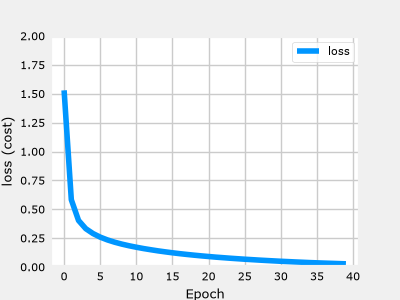

In [17]:
plot_loss_tf(history)

#### 预测
要进行预测，使用 Keras 的 `predict`。在下面，X[1015] 包含一张数字 2 的图像。

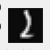

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
 predicting a Two: 
[[-6.13  4.3   8.73  4.63 -8.85 -6.9  -6.4   0.68 -3.29 -5.75]]
 Largest Prediction index: 2


In [18]:
image_of_two = X[1015]
display_digit(image_of_two)

prediction = model.predict(image_of_two.reshape(1,400))  # prediction

print(f" predicting a Two: \n{prediction}")
print(f" Largest Prediction index: {np.argmax(prediction)}")

最大的输出是 prediction[2]，表明预测的数字是 '2'。如果问题只需要做出一个选择，这就足够了。使用 NumPy 的 [argmax](https://numpy.org/doc/stable/reference/generated/numpy.argmax.html) 来选出它。如果问题需要一个概率，则需要一个 softmax：

In [19]:
prediction_p = tf.nn.softmax(prediction)

print(f" predicting a Two. Probability vector: \n{prediction_p}")
print(f"Total of predictions: {np.sum(prediction_p):0.3f}")

 predicting a Two. Probability vector: 
[[3.43e-07 1.16e-02 9.72e-01 1.62e-02 2.26e-08 1.58e-07 2.62e-07 3.10e-04
  5.85e-06 5.01e-07]]
Total of predictions: 1.000


要返回一个代表预测目标的整数，你需要最大概率所在的索引。这可以用 Numpy 的 [argmax](https://numpy.org/doc/stable/reference/generated/numpy.argmax.html) 函数来完成。

In [20]:
yhat = np.argmax(prediction_p)

print(f"np.argmax(prediction_p): {yhat}")

np.argmax(prediction_p): 2


让我们对随机抽取的 64 个数字，比较其预测与标签。这需要一点时间来运行。

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━

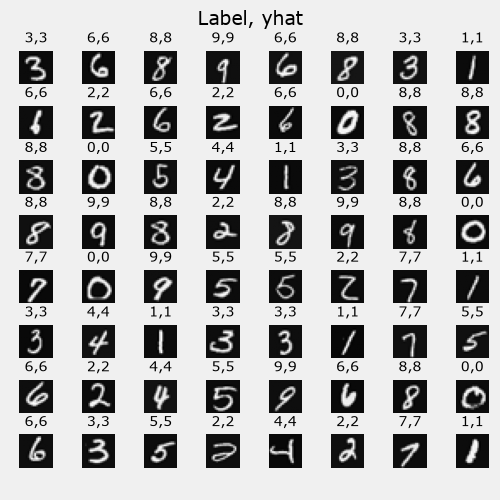

In [21]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(5,5))
fig.tight_layout(pad=0.13,rect=[0, 0.03, 1, 0.91]) #[left, bottom, right, top]
widgvis(fig)
for i,ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')
    
    # Predict using the Neural Network
    prediction = model.predict(X[random_index].reshape(1,400))
    prediction_p = tf.nn.softmax(prediction)
    yhat = np.argmax(prediction_p)
    
    # Display the label above the image
    ax.set_title(f"{y[random_index,0]},{yhat}",fontsize=10)
    ax.set_axis_off()
fig.suptitle("Label, yhat", fontsize=14)
plt.show()

让我们看看其中的一些错误。
>注意：增加训练的轮次数可以消除在这个数据集上的错误。

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 533us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
23 errors out of 5000 images


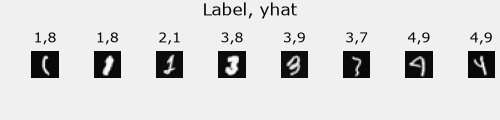

In [22]:
print( f"{display_errors(model,X,y)} errors out of {len(X)} images")

### 恭喜完成！
你已经成功地构建并使用了一个神经网络来进行多类别分类。

<details>
  <summary><font size="2" color="darkgreen"><b>如果你想试验任何不参与评分的代码，请点击这里。</b></font></summary>
    <p><i><b>重要提示：请仅在你已经通过本次作业之后再这样做，以避免自动评分器出现问题。</b></i>
    <ol>
        <li> 在笔记本的菜单上，点击 "View" > "Cell Toolbar" > "Edit Metadata"</li>
        <li> 点击你想锁定/解锁的代码单元格旁边的 "Edit Metadata" 按钮</li>
        <li> 把 "editable" 的属性值设为：
            <ul>
                <li> 如果你想解锁它，设为 "true" </li>
                <li> 如果你想锁定它，设为 "false" </li>
            </ul>
        </li>
        <li> 在笔记本的菜单上，点击 "View" > "Cell Toolbar" > "None" </li>
    </ol>
    <p> 这里有一个简短的演示，展示如何执行上述步骤：
        <br>
        <img src="https://drive.google.com/uc?export=view&id=14Xy_Mb17CZVgzVAgq7NCjMVBvSae3xO1" align="center" alt="unlock_cells.gif">
</details>